# 03 — DNABERT-2 LoRA Fine-Tuning (multi-dataset)

Aligned with `04_partial_unfreezing` notebook from coco.

**This notebook runs LoRA fine-tuning on 3 Genomic Benchmarks tasks:**
- `human_nontata_promoters`
- `human_enhancers_cohn`
- `drosophila_enhancers_stark`

Per-dataset results are saved to `./results/{DATASET_NAME}/{DATASET_NAME}_lora_*.{csv,json}` to avoid filename collisions with coco's partial-unfreezing outputs.

**Pipeline order**: 01_embedding_extraction → 02_linear_probe_training → 03_lora_finetuning (this).

## 0. Install Dependencies

In [1]:
# Pin exact versions for reproducibility
# %pip install einops transformers==4.40.0 peft omegaconf evaluate accelerate scikit-learn genomic-benchmarks
# %pip uninstall triton -y
# %pip install ipywidgets

import transformers, torch, numpy, sklearn, peft
print(f'torch:        {torch.__version__}')
print(f'transformers: {transformers.__version__}')
print(f'peft:         {peft.__version__}')
print(f'numpy:        {numpy.__version__}')
print(f'sklearn:      {sklearn.__version__}')


torch:        2.10.0+cu128
transformers: 4.40.0
peft:         0.10.0
numpy:        1.26.4
sklearn:      1.5.0


## 1. Imports & Global Config

In [2]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import random
import gc
import json
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer, AutoModel, set_seed
from peft import LoraConfig, get_peft_model
from genomic_benchmarks.dataset_getters.pytorch_datasets import get_dataset
from tqdm.notebook import tqdm

# ============ GLOBAL CONFIG ============
DATASETS = [
    'human_nontata_promoters',
    'human_enhancers_cohn',
    'drosophila_enhancers_stark',
]

SEED        = 42
MODEL_DIR   = './dnabert2'
MODEL_REPO  = 'zhihan1996/DNABERT-2-117M'
BATCH_SIZE  = 32
MAX_LENGTH  = 512
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# LoRA config — main experiment (r=8 on Wqkv + FFN)
LORA_CONFIG = {
    'r': 8,
    'lora_alpha': 16,
    'lora_dropout': 0.05,
    'target_modules': ['Wqkv', 'gated_layers', 'wo'],
}
# =======================================

print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')


def seed_everything(seed: int = SEED, deterministic: bool = True):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    set_seed(seed)
    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True)
        except Exception:
            pass
    g = torch.Generator()
    g.manual_seed(seed)

    def seed_worker(worker_id):
        worker_seed = seed + worker_id
        np.random.seed(worker_seed)
        random.seed(worker_seed)

    return g, seed_worker


seed_everything(SEED)
print(f'Seed: {SEED}')
print(f'Datasets to run: {DATASETS}')


Device: cuda
GPU: NVIDIA GeForce RTX 5090
Memory: 31.8 GB
Seed: 42
Datasets to run: ['human_nontata_promoters', 'human_enhancers_cohn', 'drosophila_enhancers_stark']


## 2. Download Model & Load Tokenizer (once)

In [3]:
# Download model if not already present
if not os.path.exists(MODEL_DIR):
    from huggingface_hub import snapshot_download
    snapshot_download(
        repo_id=MODEL_REPO,
        local_dir=MODEL_DIR,
        local_dir_use_symlinks=False,
    )
    print(f'Downloaded model to {MODEL_DIR}')
else:
    print(f'Model already exists at {MODEL_DIR}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, trust_remote_code=True)
print(f'Tokenizer loaded.')


E:\anaconda\envs\nlp_dl\lib\site-packages\huggingface_hub\file_download.py:986: UserWarning: `local_dir_use_symlinks` parameter is deprecated and will be ignored. The process to download files to a local folder has been updated and do not rely on symlinks anymore. You only need to pass a destination folder as`local_dir`.
For more details, check out https://huggingface.co/docs/huggingface_hub/main/en/guides/download#download-files-to-local-folder.
  warnings.warn(


Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

.gitattributes: 0.00B [00:00, ?B/s]

LICENSE: 0.00B [00:00, ?B/s]

generation_config.json:   0%|          | 0.00/90.0 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/468M [00:00<?, ?B/s]

Downloaded model to ./dnabert2
Tokenizer loaded.


## 3. Pooling Functions

In [4]:
def mean_pool(hidden_states, attention_mask):
    mask   = attention_mask.unsqueeze(-1).float()
    masked = hidden_states * mask
    summed = masked.sum(dim=1)
    counts = mask.sum(dim=1).clamp(min=1e-9)
    return summed / counts


def max_pool(hidden_states, attention_mask):
    mask = attention_mask.unsqueeze(-1).float()
    h = hidden_states.clone()
    h[mask.squeeze(-1) == 0] = float('-inf')
    return h.max(dim=1)[0]


def cls_pool(hidden_states, attention_mask):
    return hidden_states[:, 0, :]


POOLING_FNS = {'mean': mean_pool, 'max': max_pool, 'cls': cls_pool}
print('Pooling methods:', list(POOLING_FNS.keys()))


Pooling methods: ['mean', 'max', 'cls']


## 4. LoRA Model

In [5]:
class LoraDNABERT2(nn.Module):
    def __init__(self, model_dir, lora_cfg, num_labels=2, pooling='mean', dropout=0.1):
        super().__init__()
        backbone = AutoModel.from_pretrained(model_dir, trust_remote_code=True)

        lora_config = LoraConfig(
            r=lora_cfg['r'],
            lora_alpha=lora_cfg['lora_alpha'],
            target_modules=lora_cfg['target_modules'],
            lora_dropout=lora_cfg['lora_dropout'],
            bias='none',
        )
        self.backbone = get_peft_model(backbone, lora_config)
        self.pooling  = pooling
        hidden_size   = backbone.config.hidden_size

        self.dropout = nn.Dropout(dropout)
        # MLP head — identical to partial-unfreezing notebook
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 256),
            nn.ReLU(),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Linear(32, num_labels),
        )
        self._shape_checked = False

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.backbone(input_ids=input_ids, attention_mask=attention_mask, return_dict=True)
        last_hidden = outputs[0]

        if not self._shape_checked:
            B, L = input_ids.shape
            assert last_hidden.dim() == 3, f'Expected [B,L,H] got {last_hidden.shape}'
            assert last_hidden.shape[0] == B and last_hidden.shape[1] == L, (
                f'Shape mismatch: input_ids {input_ids.shape}, last_hidden {last_hidden.shape}'
            )
            print(f'[shape check] input_ids {tuple(input_ids.shape)} -> last_hidden {tuple(last_hidden.shape)}')
            self._shape_checked = True

        if self.pooling == 'mean':
            x = mean_pool(last_hidden, attention_mask)
        elif self.pooling == 'max':
            x = max_pool(last_hidden, attention_mask)
        elif self.pooling == 'cls':
            x = cls_pool(last_hidden, attention_mask)
        else:
            raise ValueError(f'Unknown pooling: {self.pooling}')

        x = self.dropout(x)
        logits = self.classifier(x)
        return logits


## 5. Dataset Wrapper

Reusable wrapper — instantiated separately for each dataset in the loop below.

In [6]:
class DnaDataset(Dataset):
    def __init__(self, base_dataset, tokenizer, max_length=MAX_LENGTH):
        self.base_dataset = base_dataset
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        sequence, label = self.base_dataset[idx]
        encoding = self.tokenizer(
            sequence,
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt',
        )
        item = {key: val.squeeze(0) for key, val in encoding.items()}
        item['labels'] = torch.tensor(label, dtype=torch.long)
        return item


def make_loaders(dataset_name):
    """Build train/val/test DataLoaders for one dataset.
    
    Uses the same stratified 90/10 train/val split as coco's notebook (random_state=SEED)
    so the val set is identical across LoRA / partial-unfreezing experiments.
    """
    train_gb = get_dataset(dataset_name, split='train')
    test_gb  = get_dataset(dataset_name, split='test')

    print(f'  Train samples: {len(train_gb)}, Test samples: {len(test_gb)}')

    train_ds = DnaDataset(train_gb, tokenizer)
    test_ds  = DnaDataset(test_gb, tokenizer)

    labels_all = np.array([label for _, label in train_gb])
    all_idx = np.arange(len(train_gb))
    train_idx, val_idx = train_test_split(
        all_idx, test_size=0.1, random_state=SEED, stratify=labels_all
    )
    train_subset = Subset(train_ds, train_idx.tolist())
    val_subset   = Subset(train_ds, val_idx.tolist())

    g, seed_worker = seed_everything(SEED)
    train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True,
                              generator=g, worker_init_fn=seed_worker)
    val_loader   = DataLoader(val_subset,   batch_size=BATCH_SIZE, shuffle=False)
    test_loader  = DataLoader(test_ds,      batch_size=BATCH_SIZE, shuffle=False)

    print(f'  Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}')
    return train_loader, val_loader, test_loader


## 6. Training Utilities

In [7]:
def build_optimizer(model, head_lr=1e-3, backbone_lr=1e-4, weight_decay=0.01):
    head_params, backbone_params = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if 'classifier' in name:
            head_params.append(p)
        else:
            backbone_params.append(p)
    optimizer = torch.optim.AdamW(
        [
            {'params': head_params,     'lr': head_lr},
            {'params': backbone_params, 'lr': backbone_lr},
        ],
        weight_decay=weight_decay,
    )
    return optimizer


def evaluate(model, loader, device=DEVICE):
    model.to(device)
    model.eval()
    total_loss = 0.0
    all_preds, all_true = [], []
    loss_fn = nn.CrossEntropyLoss()
    with torch.no_grad():
        for batch in tqdm(loader, desc='Evaluating', leave=False):
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)
            logits = model(input_ids, attention_mask)
            preds  = logits.argmax(dim=1)
            loss   = loss_fn(logits, labels)
            total_loss += loss.item()
            all_preds.extend(preds.cpu().numpy())
            all_true.extend(labels.cpu().numpy())
    acc = accuracy_score(all_true, all_preds)
    f1  = f1_score(all_true, all_preds, average='macro')
    mcc = matthews_corrcoef(all_true, all_preds)
    return total_loss / len(loader), acc, f1, mcc


def train_ft(model, train_loader, val_loader, epochs=15,
             head_lr=1e-3, backbone_lr=1e-4, device=DEVICE):
    model.to(device)
    optimizer = build_optimizer(model, head_lr, backbone_lr)
    loss_fn = nn.CrossEntropyLoss()

    best_f1 = -1
    best_state = None

    history = {'epoch': [], 'train_loss': [], 'val_loss': [],
               'val_acc': [], 'val_f1': [], 'val_mcc': []}

    for epoch in tqdm(range(epochs), desc='Epochs', position=0):
        model.train()
        total_loss = 0.0
        for batch in tqdm(train_loader, desc=f'Train {epoch+1}', leave=False, position=1):
            input_ids      = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels         = batch['labels'].to(device)

            logits = model(input_ids, attention_mask)
            loss   = loss_fn(logits, labels)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item()

        val_loss, acc, f1, mcc = evaluate(model, val_loader)
        train_loss = total_loss / len(train_loader)

        history['epoch'].append(epoch + 1)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(acc)
        history['val_f1'].append(f1)
        history['val_mcc'].append(mcc)

        print(f'Epoch {epoch+1}/{epochs} | train_loss={train_loss:.4f} | '
              f'val_loss={val_loss:.4f} | acc={acc:.4f} | f1={f1:.4f} | mcc={mcc:.4f}')

        if f1 > best_f1:
            best_f1 = f1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    # Restore best-val-F1 state — same protocol as coco's notebook
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history


def cleanup():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()


print('Utilities defined. results / histories containers initialized.')


Utilities defined. results / histories containers initialized.


## 7. Run LoRA on all datasets × all pooling strategies

**Pooling ablation**: for each dataset, train 3 LoRA models with `mean` / `max` / `cls` pooling. Total: 3 datasets × 3 poolings = **9 LoRA runs**.

Estimated time: ~3 hours total on a single GPU (15 epochs each, drosophila ~10 min, human datasets ~30-40 min each).

Outputs per dataset (`./results/{dataset}/`):
- `{dataset}_lora_summary.csv` — 3 rows (one per pooling variant)
- `{dataset}_lora_histories.json` — 3 history entries
- `{dataset}_lora_val_*_curve.png` — 3-line plots (one curve per pooling)


  DATASET: human_nontata_promoters
  Train samples: 27097, Test samples: 9034
  Train batches: 763, Val batches: 85, Test batches: 283

--- Pooling: mean ---


C:\Users\JxxC\.cache\huggingface\modules\transformers_modules\dnabert2\bert_layers.py:126: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at ./dnabert2 and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epochs:   0%|          | 0/15 [00:00<?, ?it/s]

Train 1:   0%|          | 0/763 [00:00<?, ?it/s]

[shape check] input_ids (32, 512) -> last_hidden (32, 512, 768)


Evaluating:   0%|          | 0/85 [00:00<?, ?it/s]

... (141 outputs left out)

Evaluating:   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 15/15 | train_loss=0.0306 | val_loss=0.7673 | acc=0.9162 | f1=0.9162 | mcc=0.8428


Evaluating:   0%|          | 0/283 [00:00<?, ?it/s]

  test_loss=0.4240 | acc=0.9400 | f1=0.9397 | mcc=0.8804

Saved: ./results/human_nontata_promoters\human_nontata_promoters_lora_summary.csv
Saved: ./results/human_nontata_promoters\human_nontata_promoters_lora_histories.json


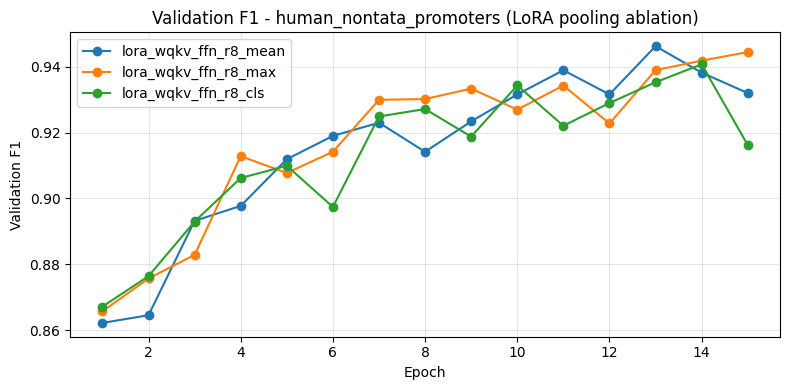

Saved: ./results/human_nontata_promoters\human_nontata_promoters_lora_val_f1_curve.png


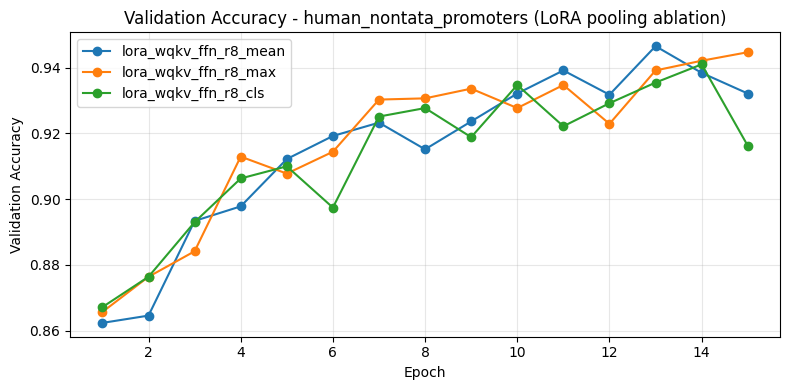

Saved: ./results/human_nontata_promoters\human_nontata_promoters_lora_val_acc_curve.png


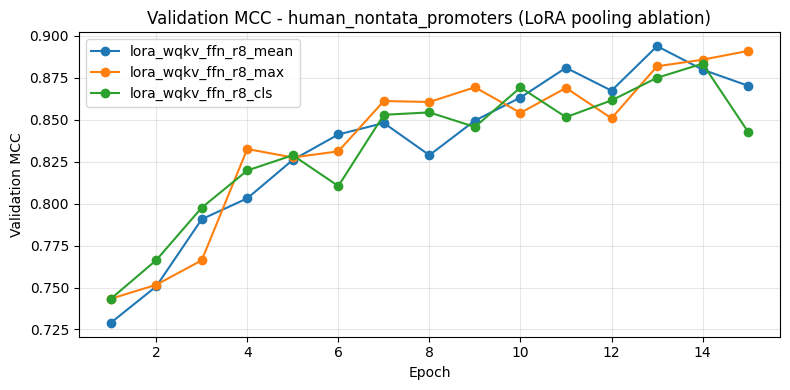

Saved: ./results/human_nontata_promoters\human_nontata_promoters_lora_val_mcc_curve.png

  DATASET: human_enhancers_cohn
  Train samples: 20843, Test samples: 6948


C:\Users\JxxC\.cache\huggingface\modules\transformers_modules\dnabert2\bert_layers.py:126: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at ./dnabert2 and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Train batches: 587, Val batches: 66, Test batches: 218

--- Pooling: mean ---


Epochs:   0%|          | 0/15 [00:00<?, ?it/s]

Train 1:   0%|          | 0/587 [00:00<?, ?it/s]

[shape check] input_ids (32, 512) -> last_hidden (32, 512, 768)


... (142 outputs left out)

Evaluating:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch 15/15 | train_loss=0.1110 | val_loss=1.5006 | acc=0.7448 | f1=0.7441 | mcc=0.4928


Evaluating:   0%|          | 0/218 [00:00<?, ?it/s]

  test_loss=0.5086 | acc=0.7648 | f1=0.7644 | mcc=0.5316

Saved: ./results/human_enhancers_cohn\human_enhancers_cohn_lora_summary.csv
Saved: ./results/human_enhancers_cohn\human_enhancers_cohn_lora_histories.json


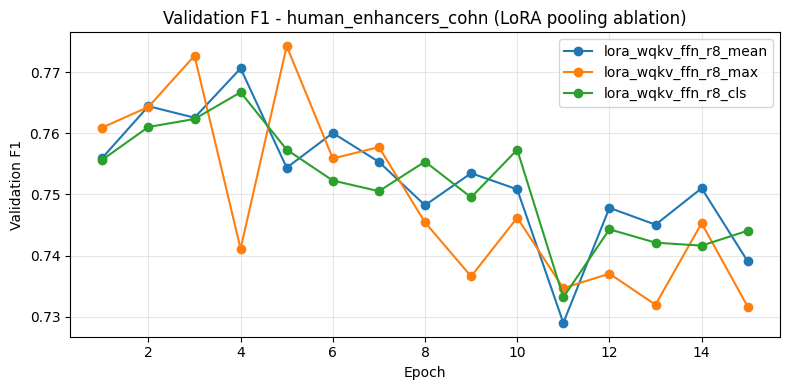

Saved: ./results/human_enhancers_cohn\human_enhancers_cohn_lora_val_f1_curve.png


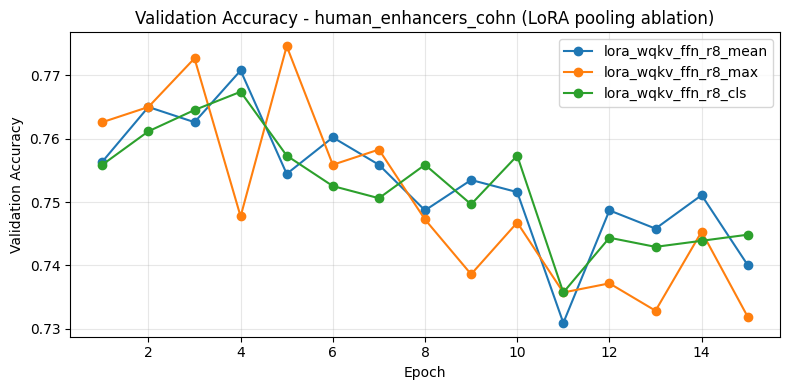

Saved: ./results/human_enhancers_cohn\human_enhancers_cohn_lora_val_acc_curve.png


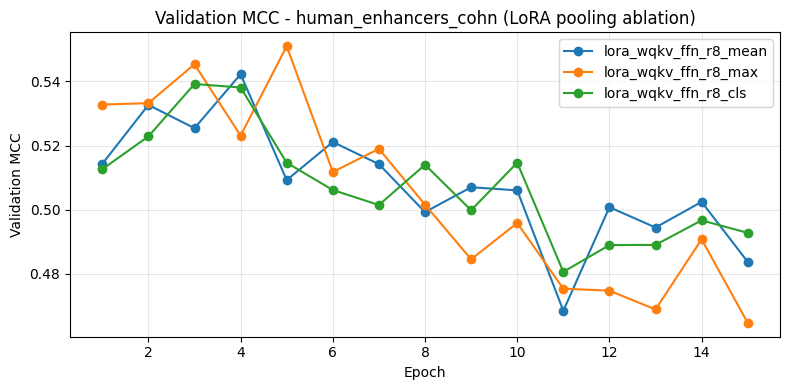

Saved: ./results/human_enhancers_cohn\human_enhancers_cohn_lora_val_mcc_curve.png

  DATASET: drosophila_enhancers_stark
  Train samples: 5184, Test samples: 1730


C:\Users\JxxC\.cache\huggingface\modules\transformers_modules\dnabert2\bert_layers.py:126: UserWarning: Unable to import Triton; defaulting MosaicBERT attention implementation to pytorch (this will reduce throughput when using this model).
  warnings.warn(
Some weights of BertModel were not initialized from the model checkpoint at ./dnabert2 and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Train batches: 146, Val batches: 17, Test batches: 55

--- Pooling: mean ---


Epochs:   0%|          | 0/15 [00:00<?, ?it/s]

Train 1:   0%|          | 0/146 [00:00<?, ?it/s]

[shape check] input_ids (32, 512) -> last_hidden (32, 512, 768)


... (142 outputs left out)

Evaluating:   0%|          | 0/17 [00:00<?, ?it/s]

Epoch 15/15 | train_loss=0.1713 | val_loss=1.0212 | acc=0.7726 | f1=0.7701 | mcc=0.5586


Evaluating:   0%|          | 0/55 [00:00<?, ?it/s]

  test_loss=0.5328 | acc=0.7653 | f1=0.7650 | mcc=0.5321

Saved: ./results/drosophila_enhancers_stark\drosophila_enhancers_stark_lora_summary.csv
Saved: ./results/drosophila_enhancers_stark\drosophila_enhancers_stark_lora_histories.json


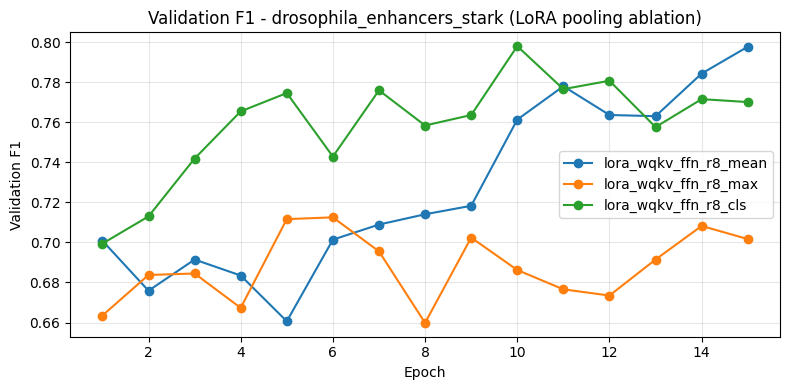

Saved: ./results/drosophila_enhancers_stark\drosophila_enhancers_stark_lora_val_f1_curve.png


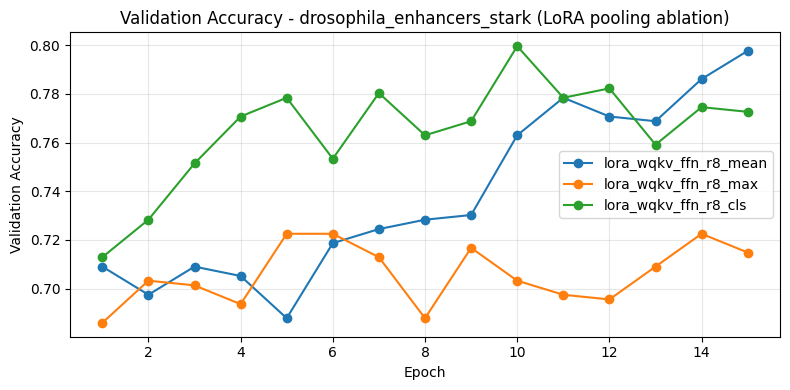

Saved: ./results/drosophila_enhancers_stark\drosophila_enhancers_stark_lora_val_acc_curve.png


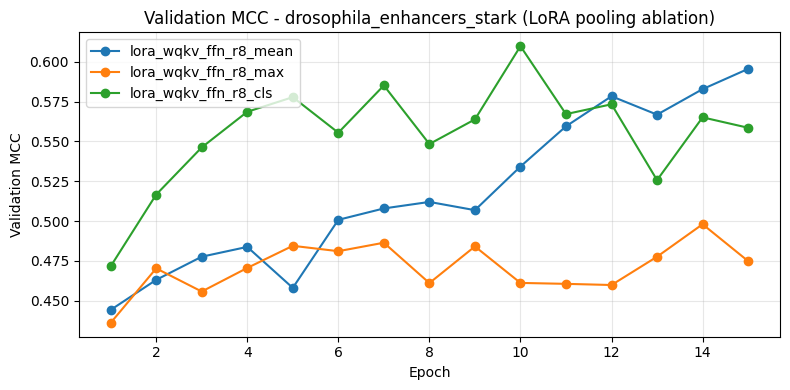

Saved: ./results/drosophila_enhancers_stark\drosophila_enhancers_stark_lora_val_mcc_curve.png

  ALL DATASETS x ALL POOLINGS DONE  (9 total runs)


In [8]:
# Aggregator across datasets (for cross-dataset / cross-pooling comparisons)
all_results = []

POOLING_VARIANTS = ['mean', 'max', 'cls']    # 3 pooling strategies × 3 datasets = 9 LoRA runs

for dataset_name in DATASETS:
    print(f'\n{"=" * 70}')
    print(f'  DATASET: {dataset_name}')
    print(f'{"=" * 70}')

    RESULT_DIR = f'./results/{dataset_name}'
    os.makedirs(RESULT_DIR, exist_ok=True)

    # ----- Build loaders for this dataset (once per dataset) -----
    train_loader, val_loader, test_loader = make_loaders(dataset_name)

    # Per-dataset stores (will accumulate all 3 pooling variants)
    results = []
    histories = {}

    for pooling in POOLING_VARIANTS:
        print(f'\n--- Pooling: {pooling} ---')

        # Fresh model + fresh seed for each pooling variant
        seed_everything(SEED)
        model = LoraDNABERT2(MODEL_DIR, LORA_CONFIG, pooling=pooling).to(DEVICE)

        head_lr     = 1e-3
        backbone_lr = 1e-4
        epochs      = 15

        model, history = train_ft(model, train_loader, val_loader,
                                  epochs=epochs,
                                  head_lr=head_lr, backbone_lr=backbone_lr)

        test_loss, acc, f1, mcc = evaluate(model, test_loader)

        exp_name = f'lora_wqkv_ffn_r8_{pooling}'
        row = {
            'dataset':        dataset_name,
            'exp_name':       exp_name,
            'pooling':        pooling,
            'lora_r':         LORA_CONFIG['r'],
            'lora_alpha':     LORA_CONFIG['lora_alpha'],
            'target_modules': '+'.join(LORA_CONFIG['target_modules']),
            'head_lr':        head_lr,
            'backbone_lr':    backbone_lr,
            'epochs':         epochs,
            'test_loss':      test_loss,
            'test_acc':       acc,
            'test_f1':        f1,
            'test_mcc':       mcc,
        }
        results.append(row)
        all_results.append(row)
        histories[exp_name] = history

        print(f'  test_loss={test_loss:.4f} | acc={acc:.4f} | f1={f1:.4f} | mcc={mcc:.4f}')

        del model
        cleanup()

    # ----- Save per-dataset summary + history (3 pooling variants together) -----
    df = pd.DataFrame(results)
    csv_path = os.path.join(RESULT_DIR, f'{dataset_name}_lora_summary.csv')
    df.to_csv(csv_path, index=False)
    print(f'\nSaved: {csv_path}')

    json_path = os.path.join(RESULT_DIR, f'{dataset_name}_lora_histories.json')
    with open(json_path, 'w') as f:
        json.dump(histories, f, indent=2)
    print(f'Saved: {json_path}')

    # ----- Per-dataset val curves (3 pooling overlaid per metric) -----
    line_metrics = [('val_f1', 'Validation F1'),
                    ('val_acc', 'Validation Accuracy'),
                    ('val_mcc', 'Validation MCC')]
    for key, title in line_metrics:
        plt.figure(figsize=(8, 4))
        for name, hist in histories.items():
            plt.plot(hist['epoch'], hist[key], marker='o', label=name)
        plt.xlabel('Epoch'); plt.ylabel(title)
        plt.title(f'{title} - {dataset_name} (LoRA pooling ablation)')
        plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout()
        fig_path = os.path.join(RESULT_DIR, f'{dataset_name}_lora_{key}_curve.png')
        plt.savefig(fig_path, dpi=200, bbox_inches='tight')
        plt.show()
        print(f'Saved: {fig_path}')

print(f'\n{"=" * 70}')
print(f'  ALL DATASETS x ALL POOLINGS DONE  ({len(all_results)} total runs)')
print(f'{"=" * 70}')


## 8. Cross-Dataset Summary — 6-method comparison (TEST set)

Compares 3 partial-unfreezing methods (Coco's, mean pooling) against 3 LoRA pooling variants (mean / max / cls) across all 3 datasets.

Reads from disk:
- **Coco's** `{dataset}_summary.csv` → baseline + unfreeze_last4 + progressive (mean pooling)
- **Your LoRA** `{dataset}_lora_summary.csv` → 3 pooling variants

Outputs:
- `./results/all_methods_test_summary.csv` — full table (18 rows: 6 methods × 3 datasets)
- `./results/all_methods_test_metrics.png` — grouped bar chart

**Note**: if Coco also runs partial-unfreezing with CLS pooling, those numbers can be added by her writing them into her `{dataset}_summary.csv` files; this cell will pick them up automatically.

,dataset,method,method_label,pooling,trainable_pct,test_acc,test_f1,test_mcc
0,human_nontata_promoters,baseline_classifier_only,Baseline (frozen),mean,~0.17%,0.849679,0.849665,0.715761
1,human_nontata_promoters,baseline_classifier_only,Baseline (frozen),max,~0.17%,0.801417,0.801203,0.626213
2,human_nontata_promoters,baseline_classifier_only,Baseline (frozen),cls,~0.17%,0.826323,0.826285,0.670240
3,human_nontata_promoters,unfreeze_last4,Unfreeze last 4,mean,~24%,0.942440,0.941978,0.883958
4,human_nontata_promoters,unfreeze_last4,Unfreeze last 4,max,~24%,0.955944,0.955701,0.911777
5,human_nontata_promoters,unfreeze_last4,Unfreeze last 4,cls,~24%,0.929489,0.929347,0.862195
6,human_nontata_promoters,progressive_unfreeze_last4,Progressive unfreeze,mean,~24%,0.948085,0.947794,0.895931
7,human_nontata_promoters,progressive_unfreeze_last4,Progressive unfreeze,max,~24%,0.945871,0.945716,0.893718
8,human_nontata_promoters,progressive_unfreeze_last4,Progressive unfreeze,cls,~24%,0.919637,0.919549,0.844716
9,human_nontata_promoters,lora_wqkv_ffn_r8,LoRA r=8 (Wqkv+FFN),mean,1.29%,0.942440,0.942203,0.885513



Saved: ./results/all_methods_pooling_test_summary.csv  (36 rows)

Pivot: Test F1 — rows=method, cols=(dataset, pooling)
dataset                    human_nontata_promoters                 human_enhancers_cohn                 drosophila_enhancers_stark                
pooling                                       mean     max     cls                 mean     max     cls                       mean     max     cls
method                                                                                                                                            
baseline_classifier_only                    0.8497  0.8012  0.8263               0.7490  0.7131  0.7344                     0.7085  0.6918  0.7224
unfreeze_last4                              0.9420  0.9557  0.9293               0.7605  0.7576  0.7546                     0.7245  0.8106  0.7645
progressive_unfreeze_last4                  0.9478  0.9457  0.9195               0.7602  0.7526  0.7484                     0.7195  0.7648  0.75

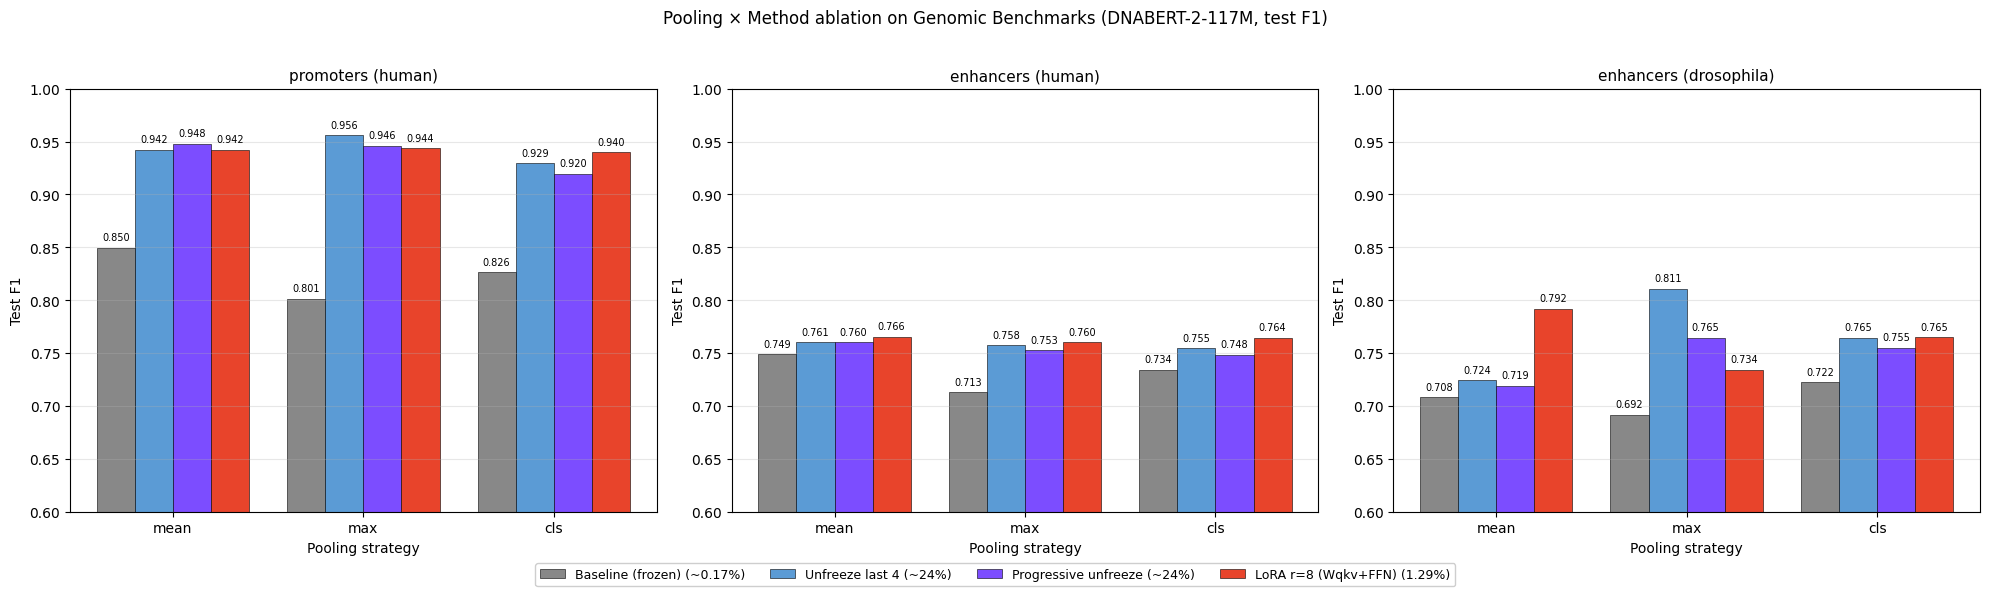


Saved: ./results/all_methods_pooling_test_metrics.png

Best pooling per (method, dataset)  →  Test F1
Dataset                          Method                        Best pool    Test F1
----------------------------------------------------------------------------------------
human_nontata_promoters          Baseline (frozen)                  mean     0.8497
human_nontata_promoters          Unfreeze last 4                     max     0.9557
human_nontata_promoters          Progressive unfreeze               mean     0.9478
human_nontata_promoters          LoRA r=8 (Wqkv+FFN)                 max     0.9437
----------------------------------------------------------------------------------------
human_enhancers_cohn             Baseline (frozen)                  mean     0.7490
human_enhancers_cohn             Unfreeze last 4                    mean     0.7605
human_enhancers_cohn             Progressive unfreeze               mean     0.7602
human_enhancers_cohn             LoRA r=8 (Wqkv

In [10]:
import json
import os
import numpy as np

# ============ Read coco's partial-unfreezing pooling ablation ============
# Expects merged CSV with 9 rows per dataset (3 methods × 3 poolings)
# CSV columns: exp_name, exp_name_pool, pooling, test_acc, test_f1, test_mcc

def read_coco_pooling(dataset_name):
    """Returns dict {(exp_name, pooling): (acc, f1, mcc)}."""
    out = {}
    csv_path = f'./results/{dataset_name}/{dataset_name}_summary.csv'
    if not os.path.exists(csv_path):
        print(f'  WARN: {csv_path} not found')
        return out
    df = pd.read_csv(csv_path)
    for _, row in df.iterrows():
        # Use 'pooling' column if present, else infer from exp_name_pool suffix
        if 'pooling' in row and pd.notna(row['pooling']):
            pool = row['pooling']
        elif 'exp_name_pool' in row and pd.notna(row['exp_name_pool']):
            pool = row['exp_name_pool'].rsplit('_', 1)[-1]
        else:
            pool = 'mean'  # legacy single-pooling csvs
        out[(row['exp_name'], pool)] = (row['test_acc'], row['test_f1'], row['test_mcc'])
    return out


def read_lora_pooling(dataset_name):
    """Returns dict {pooling: (acc, f1, mcc)}."""
    out = {}
    csv_path = f'./results/{dataset_name}/{dataset_name}_lora_summary.csv'
    if not os.path.exists(csv_path):
        print(f'  WARN: {csv_path} not found')
        return out
    df = pd.read_csv(csv_path)
    for _, row in df.iterrows():
        pool = row.get('pooling', 'mean')
        out[pool] = (row['test_acc'], row['test_f1'], row['test_mcc'])
    return out


# ============ Build combined 12-row table ============
# 4 methods × 3 poolings = 12 rows per dataset
methods = [
    ('baseline_classifier_only',    'Baseline (frozen)',         '~0.17%'),
    ('unfreeze_last4',              'Unfreeze last 4',           '~24%'),
    ('progressive_unfreeze_last4',  'Progressive unfreeze',      '~24%'),
    ('lora_wqkv_ffn_r8',            'LoRA r=8 (Wqkv+FFN)',       '1.29%'),
]
POOLINGS = ['mean', 'max', 'cls']

datasets_to_plot = list(DATASETS)
rows = []
for ds in datasets_to_plot:
    coco = read_coco_pooling(ds)
    lora = read_lora_pooling(ds)
    for method_key, method_label, pct in methods:
        for pool in POOLINGS:
            if method_key.startswith('lora_'):
                triple = lora.get(pool)
            else:
                triple = coco.get((method_key, pool))
            acc, f1, mcc = triple if triple else (None, None, None)
            rows.append({
                'dataset':       ds,
                'method':        method_key,
                'method_label':  method_label,
                'pooling':       pool,
                'trainable_pct': pct,
                'test_acc':      acc,
                'test_f1':       f1,
                'test_mcc':      mcc,
            })

df_all = pd.DataFrame(rows)
display(df_all)

os.makedirs('./results', exist_ok=True)
df_all.to_csv('./results/all_methods_pooling_test_summary.csv', index=False)
print(f'\nSaved: ./results/all_methods_pooling_test_summary.csv  ({len(df_all)} rows)')


# ============ Pivot table: rows=method, cols=(dataset, pooling), values=test_f1 ============
print('\n' + '=' * 100)
print('Pivot: Test F1 — rows=method, cols=(dataset, pooling)')
print('=' * 100)
pivot = df_all.pivot_table(index='method', columns=['dataset', 'pooling'], values='test_f1')
pivot = pivot.reindex([m[0] for m in methods])
pivot = pivot.reindex(columns=pd.MultiIndex.from_product([datasets_to_plot, POOLINGS],
                                                          names=['dataset','pooling']))
print(pivot.round(4).to_string())


# ============ Plot 1: Bar chart per dataset, pooling on x-axis, methods grouped ============
short_names = {
    'human_nontata_promoters':    'promoters (human)',
    'human_enhancers_cohn':       'enhancers (human)',
    'drosophila_enhancers_stark': 'enhancers (drosophila)',
}
method_colors = {
    'baseline_classifier_only':    '#888888',
    'unfreeze_last4':              '#5b9bd5',
    'progressive_unfreeze_last4':  '#7c4dff',
    'lora_wqkv_ffn_r8':            '#e8442b',
}

# One subplot per dataset; within each subplot, x = pooling, grouped bars = methods
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

x = np.arange(len(POOLINGS))
n_methods = len(methods)
width = 0.20

for ax, ds in zip(axes, datasets_to_plot):
    for i, (method_key, method_label, pct) in enumerate(methods):
        offset = (i - (n_methods - 1) / 2) * width
        vals = []
        for pool in POOLINGS:
            row = df_all.query("dataset == @ds and method == @method_key and pooling == @pool")
            v = row['test_f1'].iloc[0] if len(row) else None
            vals.append(v)
        bars = ax.bar(x + offset, [v if v is not None else 0 for v in vals], width,
                      label=f'{method_label} ({pct})',
                      color=method_colors[method_key], edgecolor='black', linewidth=0.4)
        for bar, v in zip(bars, vals):
            if v is not None and not np.isnan(v):
                ax.text(bar.get_x() + bar.get_width()/2, v + 0.005, f'{v:.3f}',
                        ha='center', va='bottom', fontsize=7, rotation=0)
    ax.set_xticks(x)
    ax.set_xticklabels(POOLINGS, fontsize=10)
    ax.set_xlabel('Pooling strategy')
    ax.set_ylabel('Test F1')
    ax.set_title(short_names[ds], fontsize=11)
    ax.set_ylim(0.6, 1.0)
    ax.grid(True, axis='y', alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.04), framealpha=0.95)
plt.suptitle('Pooling × Method ablation on Genomic Benchmarks (DNABERT-2-117M, test F1)',
             fontsize=12, y=1.02)
plt.tight_layout()
fig_path = './results/all_methods_pooling_test_metrics.png'
plt.savefig(fig_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'\nSaved: {fig_path}')


# ============ "Best of each method" per dataset ============
print('\n' + '=' * 100)
print('Best pooling per (method, dataset)  →  Test F1')
print('=' * 100)
print(f'{"Dataset":<32} {"Method":<28} {"Best pool":>10} {"Test F1":>10}')
print('-' * 88)
for ds in datasets_to_plot:
    for method_key, method_label, _ in methods:
        sub = df_all[(df_all.dataset == ds) & (df_all.method == method_key)].dropna(subset=['test_f1'])
        if not len(sub):
            continue
        best = sub.loc[sub['test_f1'].idxmax()]
        print(f'{ds:<32} {method_label:<28} {best["pooling"]:>10} {best["test_f1"]:>10.4f}')
    print('-' * 88)


# ============ "LoRA's best vs Partial's best" per dataset ============
print('\n' + '=' * 100)
print('Best partial-unfreezing vs Best LoRA (over poolings)')
print('=' * 100)
for ds in datasets_to_plot:
    pu = df_all[(df_all.dataset == ds) &
                (df_all.method.isin(['unfreeze_last4', 'progressive_unfreeze_last4']))].dropna(subset=['test_f1'])
    lora = df_all[(df_all.dataset == ds) & (df_all.method == 'lora_wqkv_ffn_r8')].dropna(subset=['test_f1'])
    if not len(pu) or not len(lora):
        continue
    pu_best   = pu.loc[pu['test_f1'].idxmax()]
    lora_best = lora.loc[lora['test_f1'].idxmax()]
    delta = lora_best['test_f1'] - pu_best['test_f1']
    sign = '+' if delta >= 0 else ''
    note = '  ← LoRA wins' if delta > 0 else '  ← LoRA loses'
    print(f'  {ds:<32}')
    print(f'    Partial best : {pu_best["method_label"]} ({pu_best["pooling"]}) = {pu_best["test_f1"]:.4f}')
    print(f'    LoRA    best : {lora_best["method_label"]} ({lora_best["pooling"]}) = {lora_best["test_f1"]:.4f}')
    print(f'    Δ            : {sign}{delta:+.4f}{note}')
    print()
